# Лабораторная работа № 5. Классификация

**Вариант 1.** Набор `medical_diagnosis.csv`, целевой признак — `Disease`.

Цель работы — обучить и сравнить четыре метода классификации: k-ближайших соседей, дерево решений, логистическую регрессию и случайный лес. Дополнительные задания не выполняются.

## Загрузка и первичная проверка данных

Сначала проверяются размер таблицы, типы столбцов, пропуски, дубликаты и распределение целевого класса.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
DATA_PATH = Path("data/medical_diagnosis.csv")
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")

data = pd.read_csv(DATA_PATH)
print(f"Размер таблицы: {data.shape[0]} строк, {data.shape[1]} столбцов")
print(f"Пропусков: {int(data.isna().sum().sum())}")
print(f"Полных дубликатов: {int(data.duplicated().sum())}")
print("Распределение Disease:")
display(data["Disease"].value_counts().sort_index().rename_axis("Disease").to_frame("Количество"))
display(data.head())

/home/a/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Размер таблицы: 3031 строк, 14 столбцов
Пропусков: 0
Полных дубликатов: 1
Распределение Disease:


,Количество
Disease,
0,2982
1,49


,age,sex,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,smoking_status,family_history,activity_level,symptom_score,CRP_mg_L,WBC_10e9_L,ECG_result,Disease
0,34,Male,16.8,132.0,196.0,78.0,Current,No,High,0.2,0.58,8.60,Normal,0
1,24,Female,29.2,118.0,182.0,96.0,Current,No,Moderate,3.2,2.72,6.54,Normal,0
2,19,Female,16.5,121.0,268.0,101.0,Current,No,Moderate,3.8,0.18,6.61,Normal,0
3,89,Female,15.4,117.0,136.0,96.0,Never,No,Low,2.6,1.83,5.67,Normal,0
4,66,Male,16.7,82.0,241.0,126.0,Former,No,Moderate,3.5,1.16,2.66,Normal,0


## Проверка подозрительных записей

В конце исходного файла находятся 31 запись подряд, у которых одновременно `cholesterol_mg_dl > 300` и `CRP_mg_L > 20`. В остальной части файла такого сочетания показателей нет; у 26 из 31 записей холестерин дробный, хотя в остальных строках он целый. Одна строка в этой группе — точный дубликат. Совпадение положения в файле и двух экстремальных измерений указывает на отдельную загрязнённую группу, поэтому перед обучением удаляются один дубликат и 30 уникальных подозрительных записей. Это решение относится к данному файлу и не является общим правилом удаления выбросов.

Строк в подозрительной группе: 31
Из них полных дубликатов: 1
Доля дробных значений холестерина в группе: 26/31


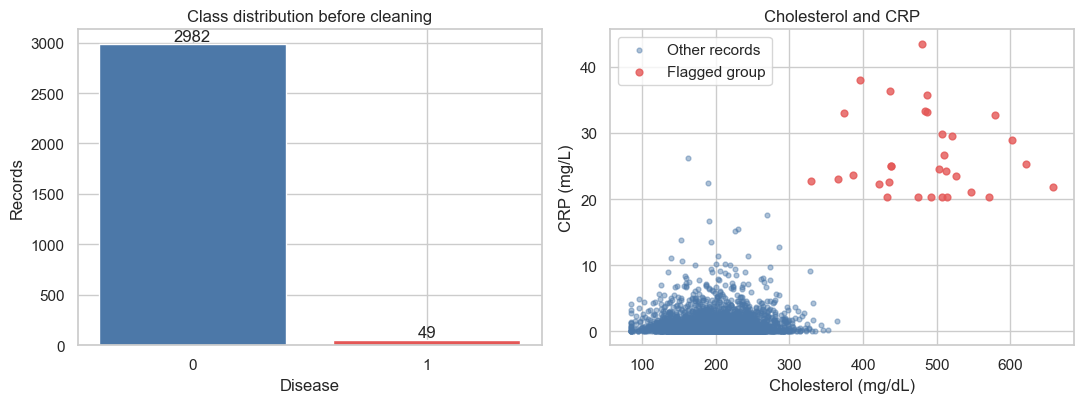

In [2]:
candidate_mask = (data["cholesterol_mg_dl"] > 300) & (data["CRP_mg_L"] > 20)
print(f"Строк в подозрительной группе: {int(candidate_mask.sum())}")
print(f"Из них полных дубликатов: {int(data.loc[candidate_mask].duplicated().sum())}")
print(f"Доля дробных значений холестерина в группе: {int((data.loc[candidate_mask, 'cholesterol_mg_dl'] % 1 != 0).sum())}/31")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
class_counts = data["Disease"].value_counts().sort_index()
axes[0].bar(class_counts.index.astype(str), class_counts.values, color=["#4C78A8", "#E45756"])
axes[0].set(title="Class distribution before cleaning", xlabel="Disease", ylabel="Records")
axes[0].bar_label(axes[0].containers[0])
axes[1].scatter(data.loc[~candidate_mask, "cholesterol_mg_dl"], data.loc[~candidate_mask, "CRP_mg_L"],
                s=12, alpha=0.45, label="Other records", color="#4C78A8")
axes[1].scatter(data.loc[candidate_mask, "cholesterol_mg_dl"], data.loc[candidate_mask, "CRP_mg_L"],
                s=24, alpha=0.8, label="Flagged group", color="#E45756")
axes[1].set(title="Cholesterol and CRP", xlabel="Cholesterol (mg/dL)", ylabel="CRP (mg/L)")
axes[1].legend(frameon=True)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "data_audit.png", dpi=180, bbox_inches="tight")
plt.show()

## Очистка данных и исследовательская визуализация

После удаления точного дубликата и подозрительной группы остаётся 3000 записей. Перед построением диаграмм целевой столбец исключается из признаков. Для читаемости матрицы рассеяния отображаются все 48 пациентов класса 1 и случайная выборка из 600 пациентов класса 0; выборка используется только для графика, а не для обучения.

После очистки: 3000 строк
Распределение Disease после очистки:


,Количество
Disease,
0,2952
1,48


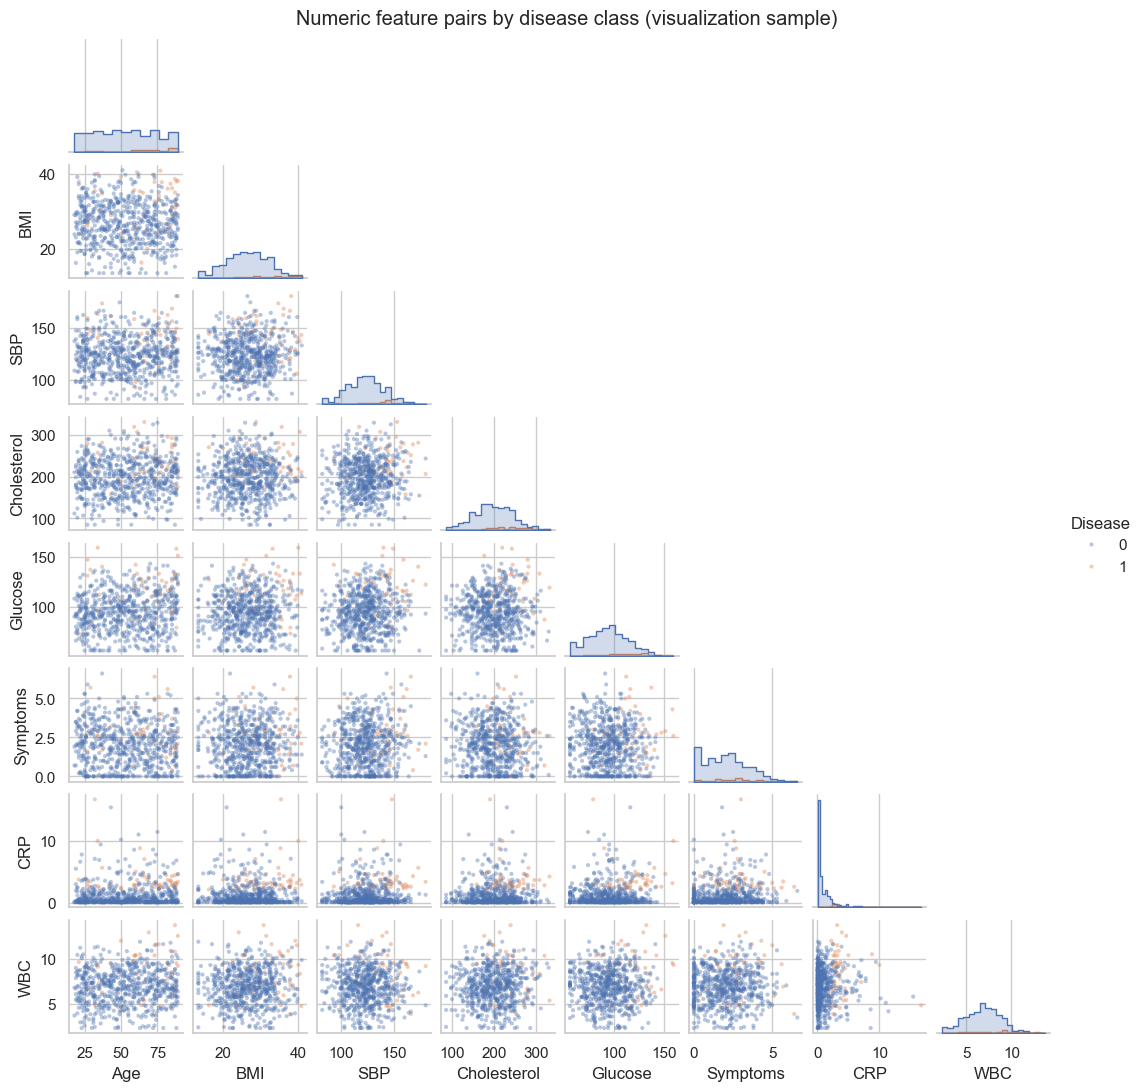

In [3]:
clean_data = data.drop_duplicates().copy()
clean_data = clean_data.loc[~candidate_mask.loc[clean_data.index]].reset_index(drop=True)
print(f"После очистки: {clean_data.shape[0]} строк")
print("Распределение Disease после очистки:")
display(clean_data["Disease"].value_counts().sort_index().rename_axis("Disease").to_frame("Количество"))

target = "Disease"
numeric_features = clean_data.drop(columns=target).select_dtypes(include=np.number).columns.tolist()
visualization_data = pd.concat([
    clean_data.loc[clean_data[target] == 1],
    clean_data.loc[clean_data[target] == 0].sample(n=600, random_state=RANDOM_STATE),
])
display_names = {
    "age": "Age", "BMI": "BMI", "systolic_bp": "SBP",
    "cholesterol_mg_dl": "Cholesterol", "fasting_glucose_mg_dl": "Glucose",
    "symptom_score": "Symptoms", "CRP_mg_L": "CRP", "WBC_10e9_L": "WBC",
}
plot_data = visualization_data.rename(columns=display_names)
pair_plot = sns.pairplot(
    plot_data,
    vars=[display_names.get(name, name) for name in numeric_features],
    hue=target,
    corner=True,
    diag_kind="hist",
    plot_kws={"s": 9, "alpha": 0.4, "linewidth": 0},
    diag_kws={"element": "step", "common_norm": False},
    height=1.35,
)
pair_plot.fig.suptitle("Numeric feature pairs by disease class (visualization sample)", y=1.01)
pair_plot.fig.savefig(IMAGE_DIR / "pairplot.png", dpi=180, bbox_inches="tight")
plt.show()

## Подготовка выборок и признаков

`Disease` — целевой признак, он не передаётся в модели. В данных 48 положительных примеров из 3000 (1,6%), поэтому выборки разделяются стратифицированно, чтобы сохранить долю классов. Искусственное балансирование не применяется: тестовая выборка должна отражать исходное распределение, а качество оценивается не только по Accuracy.

Числовые признаки стандартизируются, категориальные кодируются One-Hot. Преобразования включены в конвейер и обучаются только на тренировочной части, что исключает утечку статистик тестовой выборки.

In [4]:
X = clean_data.drop(columns=target)
y = clean_data[target].astype(int)
categorical_features = X.select_dtypes(include="object").columns.tolist()
numeric_features = X.select_dtypes(exclude="object").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), numeric_features),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ]
    )

print(f"Числовых признаков: {len(numeric_features)}; категориальных: {len(categorical_features)}")
print(f"Обучающая выборка: {len(X_train)} строк, классы {y_train.value_counts().sort_index().to_dict()}")
print(f"Тестовая выборка: {len(X_test)} строк, классы {y_test.value_counts().sort_index().to_dict()}")

Числовых признаков: 8; категориальных: 5
Обучающая выборка: 2400 строк, классы {0: 2362, 1: 38}
Тестовая выборка: 600 строк, классы {0: 590, 1: 10}


## Обучение и оценка классификаторов

Для сравнения используются параметры моделей по умолчанию, кроме фиксированного `random_state` и увеличенного лимита итераций логистической регрессии. Все модели обучаются на одной и той же выборке и через одинаковые преобразования признаков.

In [5]:
models = {
    "k-nearest neighbors": KNeighborsClassifier(),
    "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Logistic regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
"Random forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}

fitted_models = {}
predictions = {}
probabilities = {}
metric_rows = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessing", make_preprocessor()),
        ("classifier", estimator),
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_score = pipeline.predict_proba(X_test)[:, 1]
    fitted_models[name] = pipeline
    predictions[name] = y_pred
    probabilities[name] = y_score
    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_score),
    })

metrics_table = pd.DataFrame(metric_rows).set_index("Model")
display(metrics_table.round(3))

,Accuracy,Precision,Recall,Balanced accuracy,F1,ROC AUC
Model,,,,,,
k-nearest neighbors,0.987,1.000,0.2,0.600,0.333,0.792
Decision tree,0.968,0.154,0.2,0.591,0.174,0.591
Logistic regression,0.985,0.667,0.2,0.599,0.308,0.985
Random forest,0.987,1.000,0.2,0.600,0.333,0.984


## Матрицы неточностей и ROC-кривые

Матрицы неточностей построены с порядком классов `[0, 1]`. ROC-кривые всех четырёх моделей приведены на одном графике; площадь под кривой (ROC AUC) добавлена в таблицу метрик.

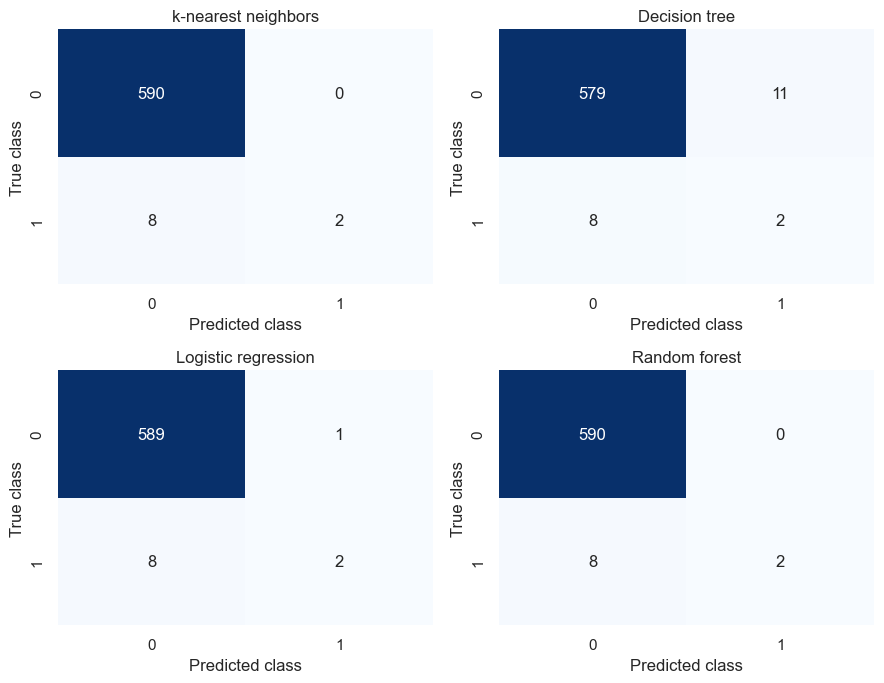

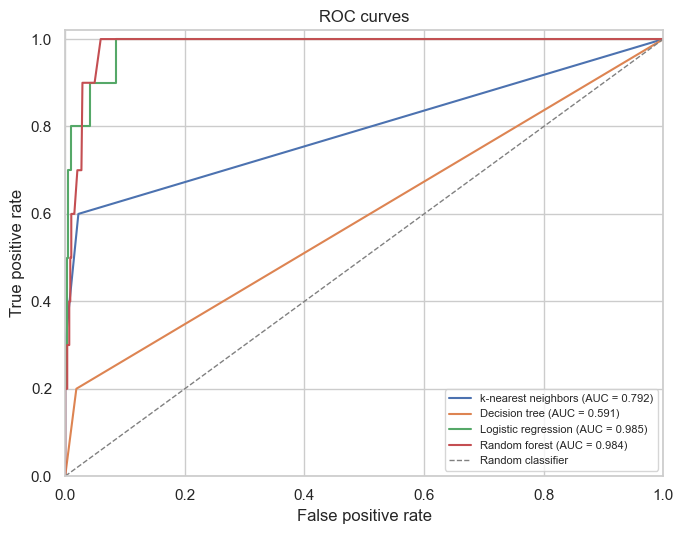

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, (name, y_pred) in zip(axes.flat, predictions.items()):
    matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["0", "1"], yticklabels=["0", "1"])
    ax.set(title=name, xlabel="Predicted class", ylabel="True class")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5.5))
for name, y_score in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_value = roc_auc_score(y_test, y_score)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Random classifier")
ax.set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "roc_curves.png", dpi=180, bbox_inches="tight")
plt.show()

## Вывод

В тестовой выборке содержится только 10 пациентов класса 1, поэтому оценки полноты и F1 чувствительны к каждому верно или неверно классифицированному пациенту. Высокую Accuracy следует трактовать вместе с полнотой, сбалансированной точностью, F1 и ROC AUC. Модель не предназначена для медицинской диагностики.